In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
# Read the dataset
# The file is assumed to be in the same directory as this script
data = pd.read_csv('pamap_balanced.csv', on_bad_lines="skip")
data.head()

,timestamp,activity_id,hand_acc_16g_x,hand_acc_16g_y,hand_acc_16g_z,hand_acc_6g_x,hand_acc_6g_y,hand_acc_6g_z,hand_gyro_x,hand_gyro_y,hand_gyro_z,hand_mag_x,hand_mag_y,hand_mag_z,subject_id
0,309.53,2,2.12462,9.24108,2.77335,2.42475,9.12390,3.02166,0.037944,0.024816,-0.016013,15.0033,-67.0045,-1.055520,1
1,309.54,2,2.33825,9.27392,2.39156,2.39424,9.13917,2.96125,0.040065,0.011347,0.009483,14.5708,-66.9884,-0.356026,1
2,309.55,2,2.22729,9.23752,2.46700,2.37879,9.21468,2.84029,0.017566,-0.017100,-0.006770,14.6740,-67.3164,-0.707928,1
3,309.56,2,2.19004,9.12433,2.50531,2.37766,9.13912,2.78006,-0.047912,0.007181,0.005693,14.7736,-67.4235,-1.288870,1
4,309.57,2,2.39182,9.23971,2.85433,2.36182,9.04862,2.78027,-0.046287,-0.000137,0.012163,15.1053,-66.5678,-1.630630,1


In [15]:
# Convert the timestamp to datetime if necessary (it might be in nanoseconds)
data['timestamp'] = pd.to_datetime(data['timestamp'], unit='s')
data.head()

,timestamp,activity_id,hand_acc_16g_x,hand_acc_16g_y,hand_acc_16g_z,hand_acc_6g_x,hand_acc_6g_y,hand_acc_6g_z,hand_gyro_x,hand_gyro_y,hand_gyro_z,hand_mag_x,hand_mag_y,hand_mag_z,subject_id
0,1970-01-01 00:05:09.530,2,2.12462,9.24108,2.77335,2.42475,9.12390,3.02166,0.037944,0.024816,-0.016013,15.0033,-67.0045,-1.055520,1
1,1970-01-01 00:05:09.540,2,2.33825,9.27392,2.39156,2.39424,9.13917,2.96125,0.040065,0.011347,0.009483,14.5708,-66.9884,-0.356026,1
2,1970-01-01 00:05:09.550,2,2.22729,9.23752,2.46700,2.37879,9.21468,2.84029,0.017566,-0.017100,-0.006770,14.6740,-67.3164,-0.707928,1
3,1970-01-01 00:05:09.560,2,2.19004,9.12433,2.50531,2.37766,9.13912,2.78006,-0.047912,0.007181,0.005693,14.7736,-67.4235,-1.288870,1
4,1970-01-01 00:05:09.570,2,2.39182,9.23971,2.85433,2.36182,9.04862,2.78027,-0.046287,-0.000137,0.012163,15.1053,-66.5678,-1.630630,1


In [17]:
# Descriptive Statistics
cols = ['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z',
        'hand_acc_6g_x', 'hand_acc_6g_y', 'hand_acc_6g_z',	
        'hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z',	
        'hand_mag_x', 'hand_mag_y', 'hand_mag_z']
print("Descriptive Statistics:")
data[cols].describe()


Descriptive Statistics:


,hand_acc_16g_x,hand_acc_16g_y,hand_acc_16g_z,hand_acc_6g_x,hand_acc_6g_y,hand_acc_6g_z,hand_gyro_x,hand_gyro_y,hand_gyro_z,hand_mag_x,hand_mag_y,hand_mag_z
count,926028.000000,926028.000000,926028.000000,926028.000000,926028.000000,926028.000000,926028.000000,926028.000000,926028.000000,926028.000000,926028.000000,926028.000000
mean,-6.762461,3.644243,2.698240,-6.696594,3.627773,2.884470,-0.011444,0.044095,-0.018340,26.236731,-15.256183,-19.102123
std,6.329207,7.595586,3.513153,6.351406,7.205481,3.514599,1.438822,1.068796,1.877079,22.677812,21.760238,18.138966
min,-145.367000,-82.550900,-101.452000,-61.214700,-61.834800,-61.934700,-27.804400,-9.139140,-14.264700,-103.941000,-200.043000,-164.937000
25%,-9.806230,1.632007,0.784627,-9.736493,1.614960,0.941805,-0.382339,-0.222926,-0.398529,8.513383,-26.547825,-29.137900
50%,-8.146780,3.375910,2.550710,-8.055005,3.434635,2.752815,-0.005999,0.006026,-0.006260,30.006300,-17.903000,-19.780400
75%,-2.296298,5.882618,4.587590,-2.175682,5.943422,4.850710,0.338189,0.277724,0.373733,42.763100,-2.323970,-7.778598
max,62.859600,155.699000,141.100000,30.031900,62.259800,61.923400,26.415800,16.917100,14.338400,137.544000,109.487000,101.758000


In [19]:
# Class Distribution
print("\nClass Distribution:")
class_counts = data['activity_id'].value_counts()
total_counts = class_counts.sum()
class_percentages = (class_counts / total_counts) * 100
print(class_counts)


Class Distribution:
activity_id
4     238761
3     189931
2     185188
12    117216
13    104944
5      98199
Name: count, dtype: int64


In [20]:
# Time Interval Analysis
data['time_diff'] = data['timestamp'].diff().dt.total_seconds()
print("\nTime Intervals (seconds):")
data['time_diff'].describe()


Time Intervals (seconds):


count    934238.000000
mean          0.003554
std           8.720748
min       -3526.200000
25%           0.010000
50%           0.010000
75%           0.010000
max         894.700000
Name: time_diff, dtype: float64

In [23]:
# Correlation Analysis
correlation_matrix = data[cols].corr().round(2)
print("\nCorrelation Matrix:")
correlation_matrix


Correlation Matrix:


,hand_acc_16g_x,hand_acc_16g_y,hand_acc_16g_z,hand_acc_6g_x,hand_acc_6g_y,hand_acc_6g_z,hand_gyro_x,hand_gyro_y,hand_gyro_z,hand_mag_x,hand_mag_y,hand_mag_z
hand_acc_16g_x,1.00,-0.07,0.26,0.99,-0.04,0.27,0.03,-0.15,0.04,-0.44,-0.09,-0.12
hand_acc_16g_y,-0.07,1.00,-0.07,-0.05,0.97,-0.07,0.14,0.03,0.04,-0.07,-0.34,0.04
hand_acc_16g_z,0.26,-0.07,1.00,0.24,-0.02,0.98,-0.05,-0.05,-0.11,-0.15,0.08,-0.30
hand_acc_6g_x,0.99,-0.05,0.24,1.00,-0.04,0.25,0.03,-0.13,0.04,-0.44,-0.09,-0.12
hand_acc_6g_y,-0.04,0.97,-0.02,-0.04,1.00,-0.03,0.08,0.02,0.07,-0.07,-0.35,0.04
hand_acc_6g_z,0.27,-0.07,0.98,0.25,-0.03,1.00,-0.04,-0.06,-0.10,-0.14,0.08,-0.30
hand_gyro_x,0.03,0.14,-0.05,0.03,0.08,-0.04,1.00,-0.24,-0.31,-0.01,-0.03,-0.00
hand_gyro_y,-0.15,0.03,-0.05,-0.13,0.02,-0.06,-0.24,1.00,0.10,-0.07,0.00,-0.01
hand_gyro_z,0.04,0.04,-0.11,0.04,0.07,-0.10,-0.31,0.10,1.00,-0.01,-0.03,0.01
hand_mag_x,-0.44,-0.07,-0.15,-0.44,-0.07,-0.14,-0.01,-0.07,-0.01,1.00,0.16,0.24


In [25]:
# Outlier Detection using Z-Score
z_scores = np.abs((data[cols] - data[cols].mean()) / data[cols].std())
outliers = (z_scores > 3).any(axis=1)
print("\nNumber of outliers detected:", outliers.sum())


Number of outliers detected: 80997


/tmp/ipykernel_20018/4035134230.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_percentages, palette='viridis')


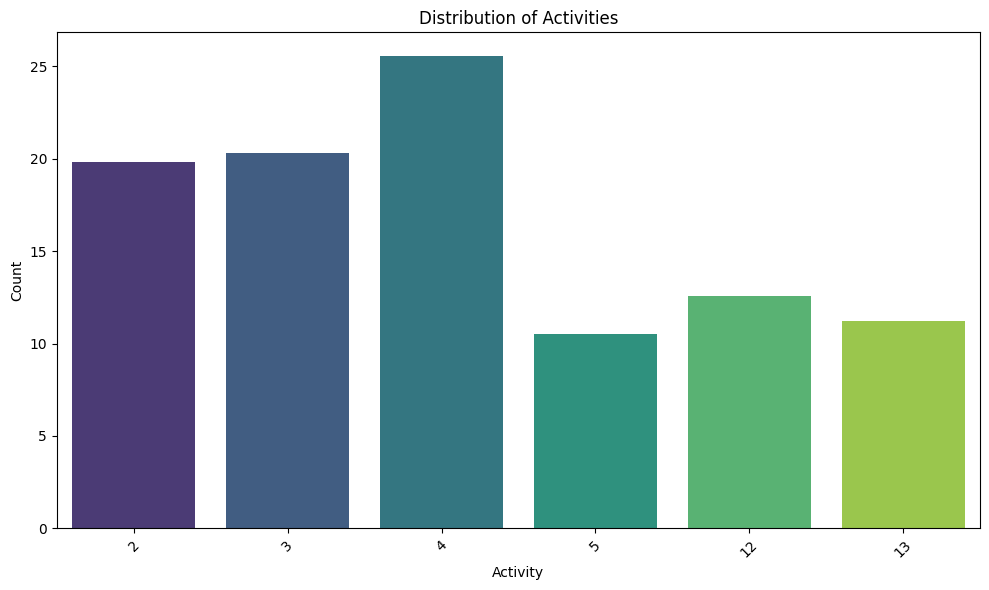

In [26]:
# Plot the class distribution
plt.figure(figsize=(10, 6))
sns.barplot(x=class_counts.index, y=class_percentages, palette='viridis')
plt.title('Distribution of Activities')
plt.xlabel('Activity')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
# # Pairwise Plot
# sns.pairplot(data, vars=['x', 'y', 'z'], hue='activity')
# plt.show()

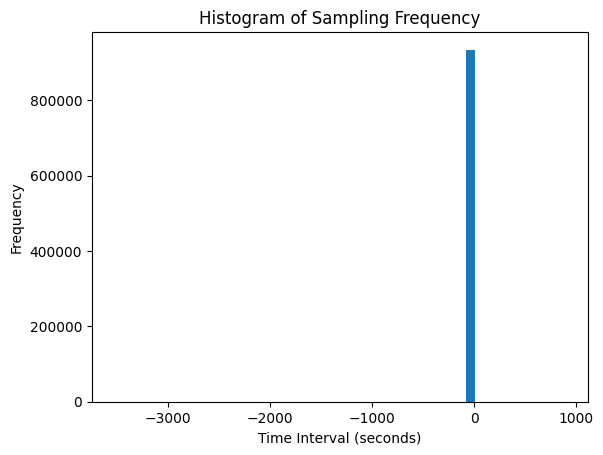

In [28]:
# Histogram of Sampling Frequency
data['time_diff'].plot(kind='hist', bins=50, title='Histogram of Sampling Frequency')
plt.xlabel('Time Interval (seconds)')
plt.show()

In [29]:
# # Fourier Transform for Signal Analysis
# fft_x = np.fft.fft(data['x'])
# fft_y = np.fft.fft(data['y'])
# fft_z = np.fft.fft(data['z'])
# freq = np.fft.fftfreq(len(fft_x))

# # Plotting the Fourier Transform
# plt.figure(figsize=(12, 6))
# plt.plot(freq, np.abs(fft_x), label='X-axis')
# plt.plot(freq, np.abs(fft_y), label='Y-axis')
# plt.plot(freq, np.abs(fft_z), label='Z-axis')
# plt.title('Fourier Transform of Accelerometer Data')
# plt.xlabel('Frequency')
# plt.ylabel('Amplitude')
# plt.legend()
# plt.show()